In [1]:
from __future__ import annotations

import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from IPython.display import display, Image

In [2]:
DATA_DIR_NAMES = [
    'upcoding_v28_top10_ha2025_export',
]
SEARCH_ROOTS = []
for root in (
    Path.cwd(),
    Path.cwd() / 'data' / 'upcoding',
    Path.cwd().parent / 'data' / 'upcoding',
    Path('/content'),
    Path('/content/data/upcoding'),
):
    if root not in SEARCH_ROOTS and root.exists():
        SEARCH_ROOTS.append(root)

OUT = Path('outputs') / 'target_prevalence_scenarios'
FIG = OUT / 'figures'
DATA_OUT = OUT / 'data'
for p in (OUT, FIG, DATA_OUT):
    p.mkdir(parents=True, exist_ok=True)

In [3]:
SCENARIOS = ['scenario_low', 'scenario_main', 'scenario_high']
SCENARIO_LABELS = {
    'scenario_low': 'Low',
    'scenario_main': 'Main',
    'scenario_high': 'High',
}
PALETTE = {
    'Baseline': '#4c78a8',
    'Low': '#72b7b2',
    'Main': '#f58518',
    'High': '#e45756',
}

HCC_SHORT = {
    'hcc36': 'Diabetes acute',
    'hcc48': 'Morbid obesity',
    'hcc93': 'RA',
    'hcc137': 'Drug use',
    'hcc139': 'Alcohol use',
    'hcc155': 'Depression',
    'hcc225': 'Heart failure',
    'hcc253': 'Hemiplegia',
    'hcc280': 'COPD/lung',
    'hcc328': 'CKD stage 3B',
}

In [4]:
# Helper functions
def resolve_data_dir() -> Path:
    candidate_dirs = [root / name for root in SEARCH_ROOTS for name in DATA_DIR_NAMES]
    for d in candidate_dirs:
        if (d / 'baseline_hier.csv').exists():
            return d

    candidate_zips = [root / f'{name}.zip' for root in SEARCH_ROOTS for name in DATA_DIR_NAMES]
    for zpath in candidate_zips:
        if zpath.exists():
            work = OUT / '_unzipped'
            if work.exists():
                shutil.rmtree(work)
            work.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zpath) as z:
                z.extractall(work)

            for candidate_file in work.rglob('baseline_hier.csv'):
                return candidate_file.parent

    searched = [str(p) for p in candidate_dirs + candidate_zips]
    raise FileNotFoundError(
        'Could not find the generated export directory or zip.\n'
        'Run the data-export notebook first, or set DATA_DIR to the export folder.\n'
        f'Searched: {searched}'
    )


def target_prevalence_diagnostics(
    data_dir: Path,
    baseline: pd.DataFrame,
    scenarios: dict[str, pd.DataFrame],
    target_map: pd.DataFrame,
) -> pd.DataFrame:
    rows = []
    for sc, df in scenarios.items():
        audit_path = data_dir / sc / 'target_audit.csv'
        if audit_path.exists():
            audit = pd.read_csv(audit_path)
            for _, r in audit.iterrows():
                h = str(r['target_hcc'])
                rows.append({
                    'scenario': sc,
                    'scenario_label': SCENARIO_LABELS[sc],
                    'target_hcc': h,
                    'target_label': HCC_SHORT.get(h, h),
                    'approach': r.get('approach', ''),
                    'diagnosis_group': r.get('diagnosis_group', ''),
                    'baseline_prev': float(baseline[h].mean()) if h in baseline.columns else np.nan,
                    'desired_prev': float(r.get('desired_prev', np.nan)),
                    'achieved_prev': float(df[h].mean()) if h in df.columns else np.nan,
                    'final_shift': float(df[h].mean() - baseline[h].mean()) if h in df.columns else np.nan,
                })
        else:
            for _, r in target_map.iterrows():
                h = str(r.get('target_hcc', r.get('hcc', '')))
                if h not in baseline.columns:
                    continue
                rows.append({
                    'scenario': sc,
                    'scenario_label': SCENARIO_LABELS[sc],
                    'target_hcc': h,
                    'target_label': HCC_SHORT.get(h, h),
                    'approach': r.get('approach', ''),
                    'diagnosis_group': r.get('diagnosis_group', r.get('v22_label', '')),
                    'baseline_prev': float(baseline[h].mean()),
                    'desired_prev': np.nan,
                    'achieved_prev': float(df[h].mean()),
                    'final_shift': float(df[h].mean() - baseline[h].mean()),
                })

    diag = pd.DataFrame(rows)
    if len(diag):
        diag['target_error'] = diag['achieved_prev'] - diag['desired_prev']
        diag['abs_target_error'] = diag['target_error'].abs()
    return diag

def plot_target_prevalence_custom(diag, version='v6'):
    if diag.empty or diag['desired_prev'].isna().all():
        print("No valid target prevalence data to plot.")
        return

    plt.rcParams.update({
        'font.size': 11.5,
        'axes.titlesize': 13.5,
        'axes.labelsize': 13.0,
        'xtick.labelsize': 11.5,
        'ytick.labelsize': 11.5,
        'legend.fontsize': 11.0,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'figure.dpi': 120,
    })

    targets = list(dict.fromkeys(diag['target_hcc']))
    fig, axes = plt.subplots(3, 1, figsize=(8.1, 10.0), sharex=True)

    for ax, sc in zip(axes, SCENARIOS):
        sub = diag[diag['scenario'].eq(sc)].set_index('target_hcc').reindex(targets)
        x = np.arange(len(targets))
        w = 0.24
        ax.bar(x - w, sub['baseline_prev'], width=w, label='Baseline', color='#4c78a8')
        ax.bar(x, sub['desired_prev'], width=w, label='Target', color='#bab0ab')
        ax.bar(x + w, sub['achieved_prev'], width=w, label='Achieved', color=PALETTE[SCENARIO_LABELS[sc]])

        ax.set_ylabel('Prevalence', fontsize=13.0)
        ax.set_title(f'{SCENARIO_LABELS[sc]} scenario', loc='center', pad=4, fontsize=13.5)
        ax.grid(axis='y', alpha=0.25, linewidth=0.5)

        ax.legend(frameon=False, ncol=3, fontsize=11.0)

        for spine in ax.spines.values():
            spine.set_visible(False)

    axes[-1].set_xticks(np.arange(len(targets)))
    axes[-1].set_xticklabels([f'{HCC_SHORT.get(h, h)}\n({h.upper()})' for h in targets], rotation=45, ha='right', fontsize=11.5)

    fig.suptitle('Target versus achieved prevalence across upcoding scenarios', y=0.997, fontsize=15.0)
    fig.tight_layout()

    png_path = FIG / f'target_vs_achieved_prevalence.png'
    fig.savefig(png_path, dpi=300, bbox_inches='tight')
    fig.savefig(FIG / f'target_vs_achieved_prevalence.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return png_path


def plot_target_shift_heatmap_custom(diag, version='v2'):
    if diag.empty:
        print("No diagnostic data available for heatmap.")
        return

    plt.rcParams.update({
        'font.size': 9.5,
        'axes.titlesize': 11.5,
        'axes.labelsize': 11.0,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 9.0,
        'figure.dpi': 120,
    })

    targets = list(dict.fromkeys(diag['target_hcc']))
    mat = diag.pivot(index='target_hcc', columns='scenario', values='final_shift').reindex(index=targets, columns=SCENARIOS)

    fig, ax = plt.subplots(figsize=(6.7, 5.6))
    im = ax.imshow(mat.values, cmap='Blues', aspect='auto')

    ax.set_xticks(range(len(SCENARIOS)))
    ax.set_xticklabels([SCENARIO_LABELS[s] for s in SCENARIOS])

    ax.set_yticks(range(len(targets)))
    ax.set_yticklabels([f"{HCC_SHORT.get(h, h)} ({h.upper()})" for h in targets])

    ax.set_title('Realized prevalence shifts by target and scenario', pad=10)

    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if np.isfinite(mat.values[i, j]):
                ax.text(j, i, f'{mat.values[i, j]:.3f}', ha='center', va='center', fontsize=9.0)

    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label('Manipulated minus baseline prevalence')

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.tight_layout()

    png_path = FIG / f'target_shift_heatmap.png'
    fig.savefig(png_path, dpi=300, bbox_inches='tight')
    fig.savefig(FIG / f'target_shift_heatmap.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return png_path


Using data directory: outputs/target_prevalence_scenarios/_unzipped/content/upcoding_v28_top10_ha2025_export
Saved:
  outputs/target_prevalence_scenarios/figures/target_vs_achieved_prevalence.pdf
  outputs/target_prevalence_scenarios/figures/target_vs_achieved_prevalence.png
  outputs/target_prevalence_scenarios/figures/target_vs_achieved_prevalence.svg
  outputs/target_prevalence_scenarios/figures/target_shift_heatmap.pdf
  outputs/target_prevalence_scenarios/figures/target_shift_heatmap.png
  outputs/target_prevalence_scenarios/figures/target_shift_heatmap.svg
  outputs/target_prevalence_scenarios/data/target_prevalence_diagnostics.csv
  outputs/target_prevalence_scenarios/data/target_prevalence_error_summary.csv

Target-prevalence error summary:


,scenario,mean_abs_error,max_abs_error
0,scenario_high,0.00026,0.0010
1,scenario_low,0.00018,0.0004
2,scenario_main,0.00014,0.0003


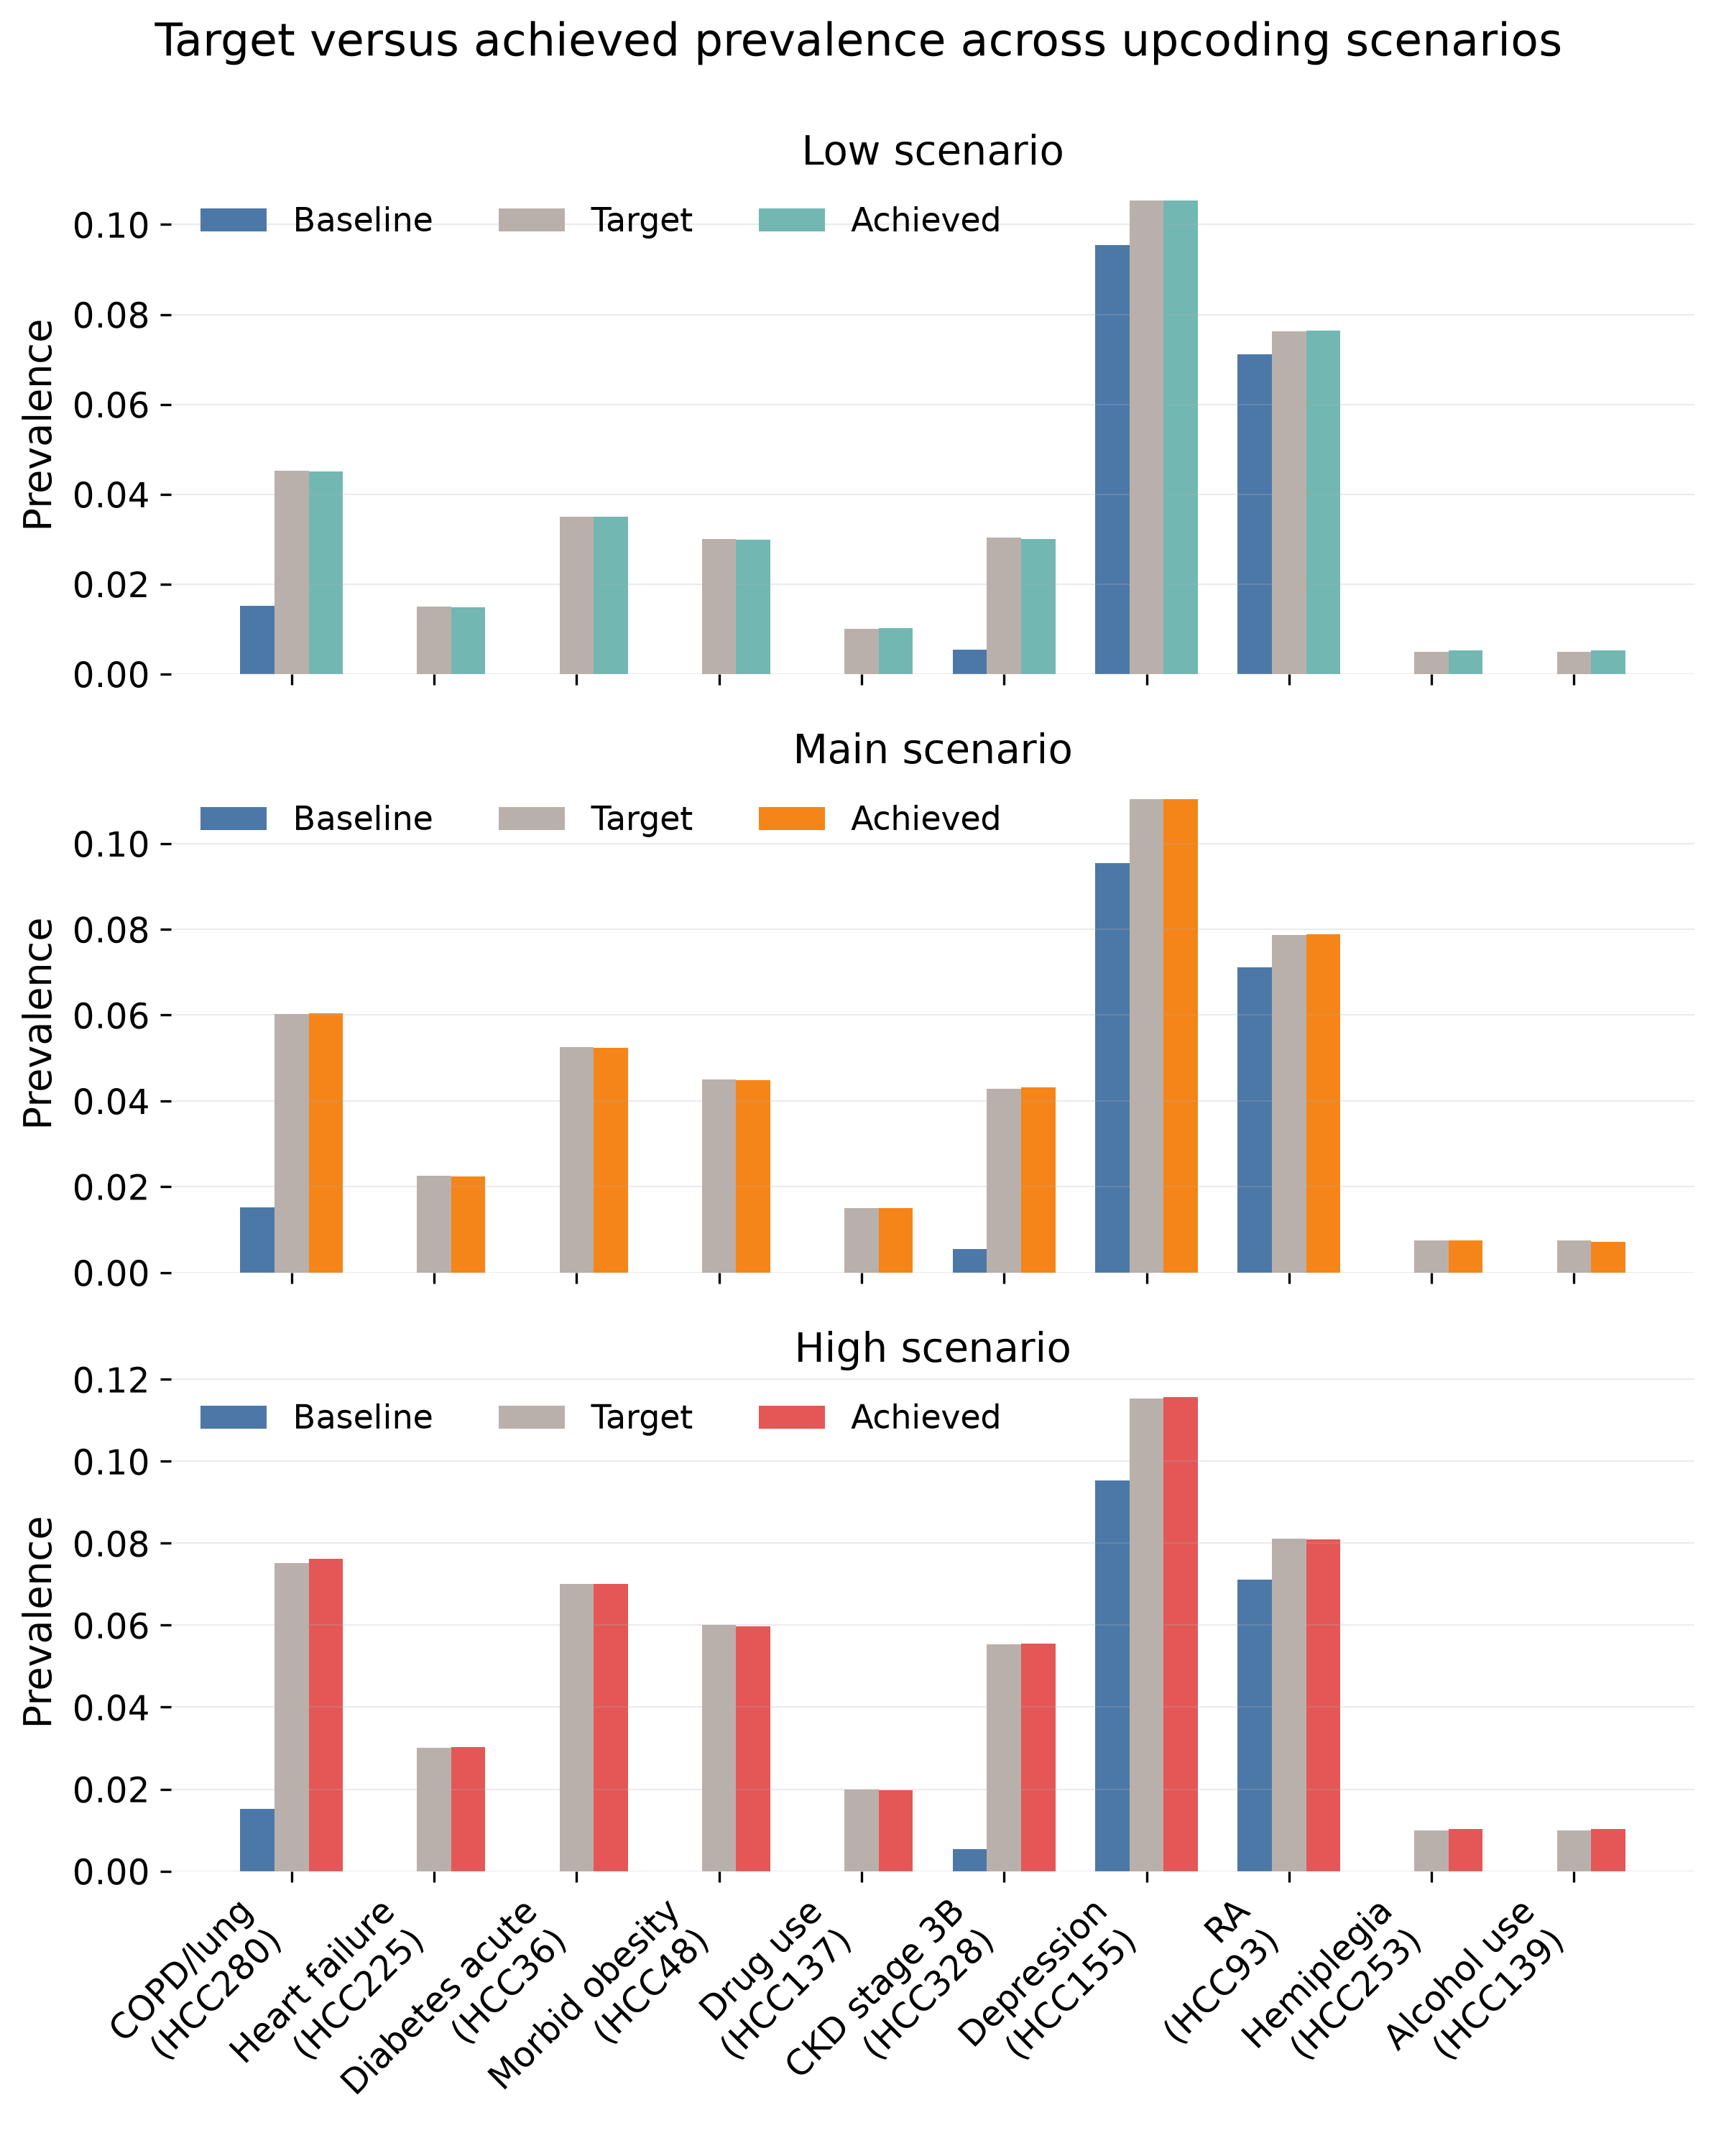

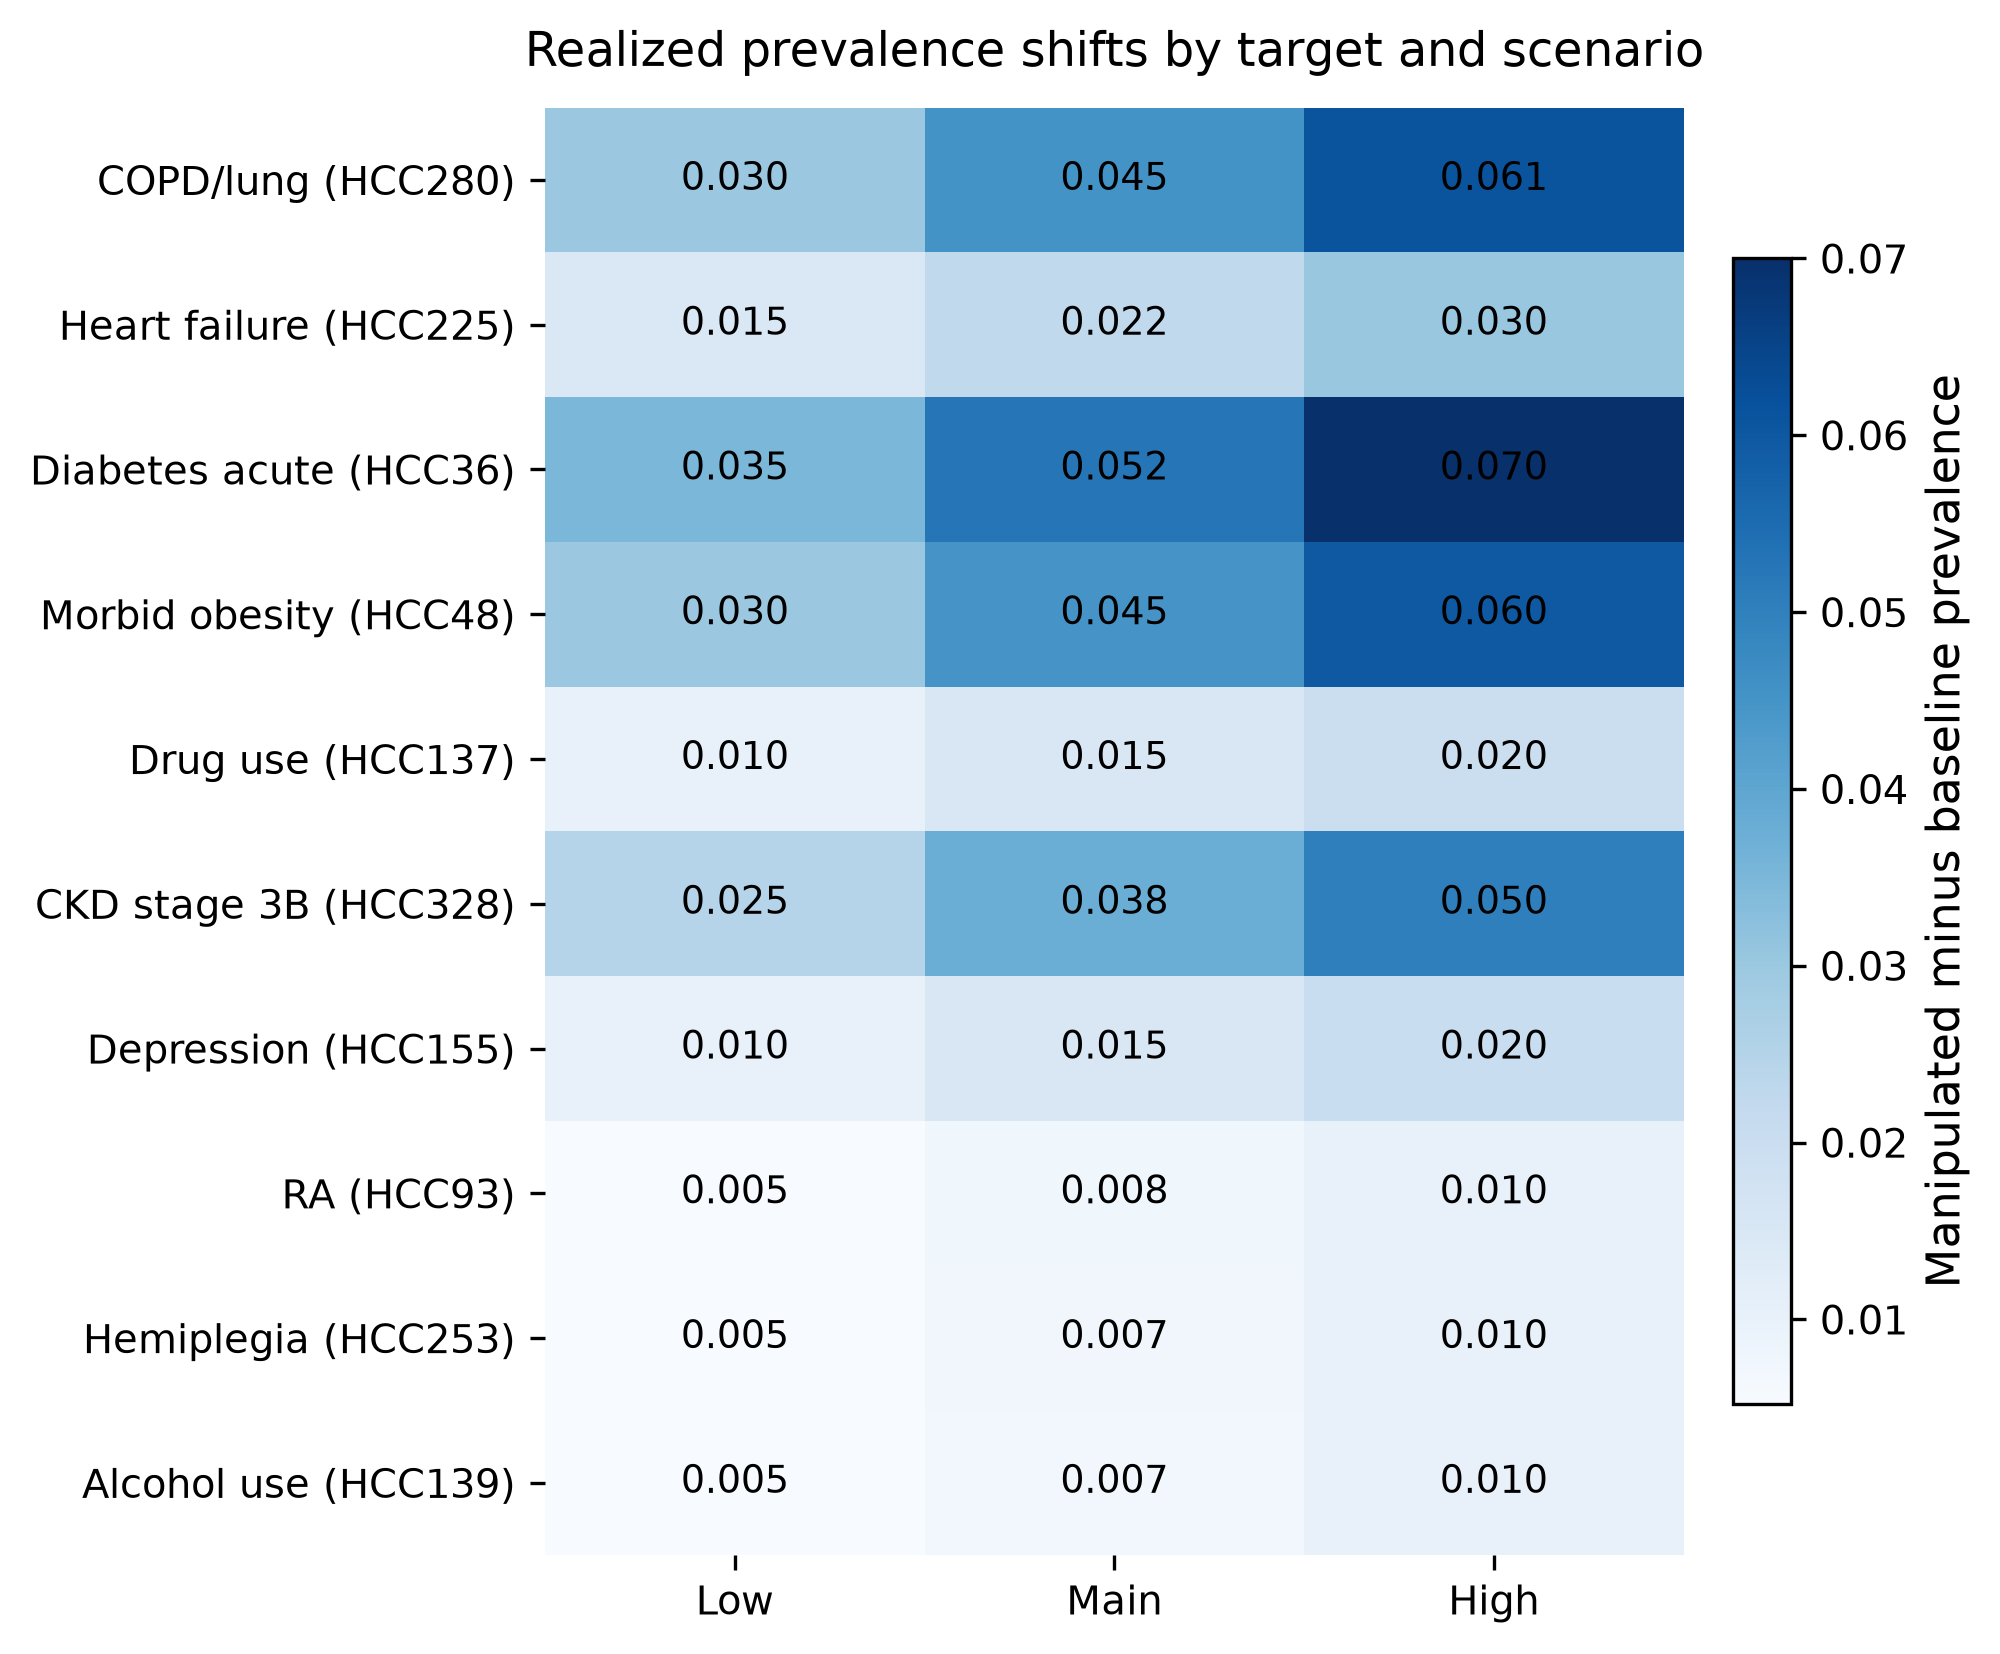

In [5]:
data_dir = resolve_data_dir()
print(f"Using data directory: {data_dir}")

baseline = pd.read_csv(data_dir / 'baseline_hier.csv')
scenarios = {
    sc: pd.read_csv(data_dir / sc / 'all_hcc_upcoded_data.csv')
    for sc in SCENARIOS
    if (data_dir / sc / 'all_hcc_upcoded_data.csv').exists()
}

missing = [sc for sc in SCENARIOS if sc not in scenarios]
if missing:
    raise FileNotFoundError(
        'Missing scenario files for: ' + ', '.join(missing) + '\n'
        'Expected files like scenario_low/all_hcc_upcoded_data.csv.'
    )

target_map = pd.read_csv(data_dir / 'target_mapping_table.csv')

diag = target_prevalence_diagnostics(data_dir, baseline, scenarios, target_map)
if diag.empty:
    raise ValueError('No target-prevalence diagnostics were produced.')

diag.to_csv(DATA_OUT / 'target_prevalence_diagnostics.csv', index=False)
error_summary = (
    diag.groupby('scenario')
    .agg(mean_abs_error=('abs_target_error', 'mean'), max_abs_error=('abs_target_error', 'max'))
    .reset_index()
)
error_summary.to_csv(DATA_OUT / 'target_prevalence_error_summary.csv', index=False)

path_prevalence = plot_target_prevalence_custom(diag)
path_heatmap = plot_target_shift_heatmap_custom(diag)

print('Saved:')
for path in [
    FIG / 'target_vs_achieved_prevalence.pdf',
    FIG / 'target_vs_achieved_prevalence.png',
    FIG / 'target_vs_achieved_prevalence.svg',
    FIG / 'target_shift_heatmap.pdf',
    FIG / 'target_shift_heatmap.png',
    FIG / 'target_shift_heatmap.svg',
    DATA_OUT / 'target_prevalence_diagnostics.csv',
    DATA_OUT / 'target_prevalence_error_summary.csv',
]:
    print(' ', path)

print('\nTarget-prevalence error summary:')
display(error_summary)

if path_prevalence is not None:
    display(Image(filename=str(path_prevalence)))
if path_heatmap is not None:
    display(Image(filename=str(path_heatmap)))